# Сохранился ли порядок направлений по числу патентных заявок?

Источник — [EPO Patent Index 2024](https://www.epo.org/en/about-us/statistics/patent-index-2024/statistics-and-indicators/european-patent-applications/all-technical-fields), срез от 03.02.2025. Включены все 8 направлений сектора Electrical engineering и все 5 направлений сектора Instruments. Одна строка — одно направление. Два числовых столбца содержат количество заявок за календарный год. Названия переведены на русский язык.

Откройте блокнот рядом с epo.csv. В Colab загрузите epo.csv в текущий каталог. Выполните ячейки сверху вниз.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("epo.csv")
for column in ["sector", "field"]:
    data[column] = data[column].str.strip()
for year in ["2023", "2024"]:
    data[year] = pd.to_numeric(data[year], errors="raise")
assert not data.isna().any().any()
assert data["field"].is_unique and len(data) == 13
assert (data[["2023", "2024"]] >= 0).all().all()
data["change"] = data["2024"] - data["2023"]
print(data[["field", "2023", "2024", "change"]].to_string(index=False))

                            field  2023  2024  change
Электрические машины и энергетика 14827 16142    1315
       Аудиовизуальные технологии  4812  5490     678
                 Телекоммуникации  5080  4657    -423
                   Цифровая связь 17065 15983   -1082
           Базовые процессы связи  1064  1099      35
          Компьютерные технологии 16284 16815     531
                  ИТ в управлении  2392  2439      47
                   Полупроводники  4246  4292      46
                           Оптика  4305  4401      96
                        Измерения  9651  9601     -50
             Анализ биоматериалов  1336  1241     -95
       Управление и регулирование  3376  3101    -275
           Медицинские технологии 16180 15701    -479


## Где число заявок изменилось сильнее всего?
Длина полосы показывает абсолютную разницу между годами в заявках. Отрицательное значение означает снижение.

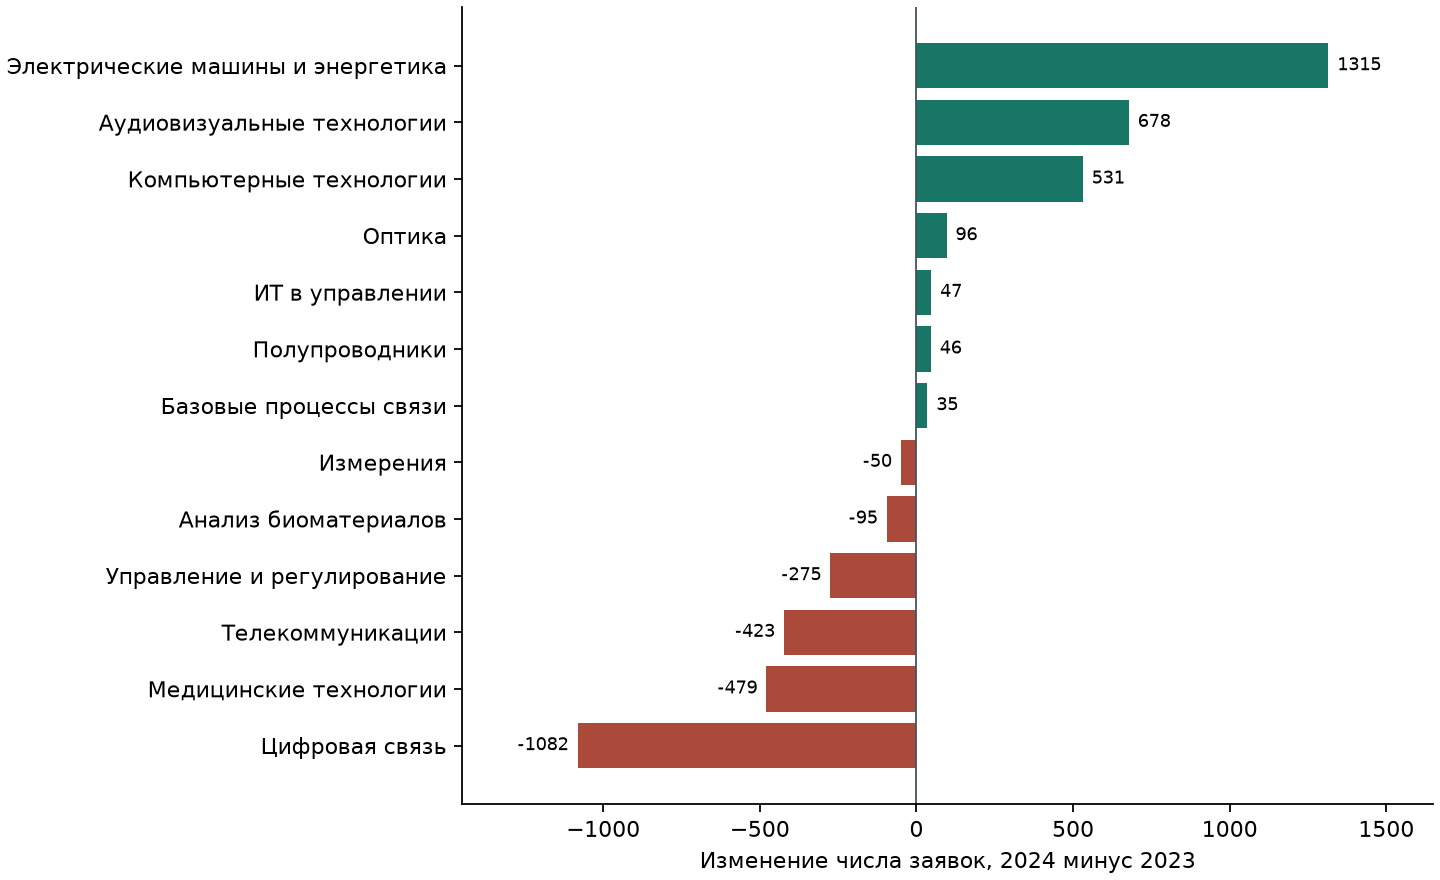

In [2]:
ordered = data.sort_values("change")
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
colors = np.where(ordered["change"] >= 0, "#187667", "#ab493a")
bars = ax.barh(ordered["field"], ordered["change"], color=colors)
ax.bar_label(bars, padding=4, fontsize=8)
ax.axvline(0, color="#44515b", linewidth=0.8)
ax.set(xlabel="Изменение числа заявок, 2024 минус 2023", xlim=(-1450, 1650))
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("change.png", dpi=160)
plt.show()

## Перестановочная проверка
H₀: при случайном сопоставлении направлений двух лет внутри каждого сектора наблюдаемое совпадение рангов объяснимо случайностью. H₁: ранги связаны положительно сильнее, чем при таком сопоставлении. Уровень значимости 0,05. Коэффициент Спирмена равен корреляции Пирсона между рангами. Сохраняем значения обоих лет и состав секторов.

In [3]:
ranks = data[["2023", "2024"]].rank()
rho = ranks["2023"].corr(ranks["2024"])
x = ranks["2023"].to_numpy() - ranks["2023"].mean()
y = ranks["2024"].to_numpy() - ranks["2024"].mean()
denominator = np.linalg.norm(x) * np.linalg.norm(y)
groups = list(data.groupby("sector").indices.values())
rng = np.random.default_rng(42)
trials = 9999
hits = 0
for _ in range(trials):
    shuffled = y.copy()
    for positions in groups:
        shuffled[positions] = rng.permutation(y[positions])
    simulated = np.dot(x, shuffled) / denominator
    hits += simulated >= rho - 1e-12
p_value = (1 + hits) / (1 + trials)
print(f"ρ = {rho:.4f}; совпадений или превышений: {hits}/{trials}; p ≈ {p_value:.4f}")

ρ = 0.9670; совпадений или превышений: 0/9999; p ≈ 0.0001


Положительная связь рангов означает, что направления с большим числом заявок в 2023 году обычно оставались вверху списка в 2024 году. Проверка относится к этим двум секторам и заданной модели перестановок. По двум годам нельзя установить причину изменений или оценить долгосрочный тренд.